# BayAir: pollution, asthma, and the limits of prediction

**Ronish Shrestha · Bay Area counties only · Local VS Code research study**

This project asks three connected questions:

1. Which Bay Area counties have higher pollution measurements?
2. Which have higher asthma-related emergency-visit indicators?
3. Can machine learning estimate the asthma indicator in a county it never trained on?

The charts answer the first two questions. The buffered ML experiment tests the third. All descriptions, training, tuning, calibration and evaluation use **only the nine Bay Area counties**. This is historical research, not a forecast or an individual health assessment.

## Run in VS Code

Open `BayAir.code-workspace`, choose the repository `.venv` kernel and **Run All**. Install the pinned dependencies first. From the repository root, `python run_bayair.py train` rebuilds all results. The notebook reads the generated evidence and verifies its data/protocol hashes; if reports are missing, run training first.

The source-checkout launcher and the path bootstrap below avoid Colab, Drive mounts and reliance on an editable installation.

In [1]:
import os, sys, json
from pathlib import Path
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Bay_Area_Health_and_Pollution_Analysis' / 'src').is_dir())
sys.path.insert(0, str(repo / 'Bay_Area_Health_and_Pollution_Analysis' / 'src'))
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('MPLCONFIGDIR', str(repo / '.venv' / 'mpl'))
import pandas as pd
from IPython.display import display, Image, Markdown
from bayair.data import PROJECT, GROUP, TARGET, COUNTIES
from bayair.official import DATA, OFFICIAL_FEATURES, load_official, sha256
from bayair.story import county_summary
reports = PROJECT / 'reports'
frame = load_official(labeled=False)
labeled = load_official()
provenance = json.loads((DATA / 'provenance.json').read_text())
assert set(frame[GROUP]) == COUNTIES
print(f'{len(frame):,} Bay Area tracts; {len(labeled):,} observed asthma labels; {frame[GROUP].nunique()} counties')
print('Official source workbook SHA-256:', provenance['workbook_sha256'])
print('Processed Bay Area SHA-256:', provenance['processed_sha256'])

1,581 Bay Area tracts; 1,580 observed asthma labels; 9 counties
Official source workbook SHA-256: 03f88d03e2fce5a04191dc65f2793e1dd8bf312b8d67a41e99ccf209b62b2f68
Processed Bay Area SHA-256: 6b47d2b2c392dd4eea865c99056b81b939ef0a11b79d944f89bfcd54e769360f


## 1. Understand the source before interpreting a chart

The source is the **official CES 4.0 final workbook**, downloaded from California's Open Data Portal. Its statewide workbook is filtered immediately to the nine Bay Area counties. That source scope is not the model's scope.

The asthma target is a spatially modeled, age-adjusted emergency-department visit rate per 10,000 people, averaged over 2015–2017. It measures emergency visits, not how many residents have asthma. Pollution and socioeconomic indicators use their own historical periods. This release does not describe present-day conditions.

The old draft extract stays unchanged. A tract-by-tract reconciliation shows which measurements agree with the final release and which differ.

In [2]:
display(pd.Series({k: provenance[k] for k in ['release', 'source_url', 'raw_rows', 'processed_rows', 'counties', 'missing_target']}))
display(pd.read_csv(reports / 'draft_final_reconciliation.csv').round(4))

release                            CalEnviroScreen 4.0 final (2021)
source_url        https://data.ca.gov/dataset/11eb2b90-f3c1-46b4...
raw_rows                                                       8035
processed_rows                                                 1581
counties                                                          9
missing_target                                                    1
dtype: object

,feature,matched_nonmissing,changed_values,mean_absolute_difference
0,Asthma,1580,0,0.0000
1,Ozone,1581,1581,0.0021
2,PM2.5,1581,0,0.0000
3,Diesel PM,1581,1572,0.0002
4,Drinking Water,1578,1578,51.5745
5,Lead,1568,1568,2.6336
6,Pesticides,1581,511,5.6730
7,Tox. Release,1581,1581,142.9985
8,Traffic,1576,0,0.0000
9,Cleanup Sites,1581,738,1.6175


## 2. Which counties have higher pollution and asthma indicators?

A county can be highest for one pollutant and lower for another. We report **unweighted means across its census tracts**, with nonmissing counts. These are not official population-aggregated county rates.

Compare the two charts: the highest-pollution county does not automatically have the highest asthma indicator. That is why a visual correlation alone is not a causal explanation.

,county,Pollution Burden,PM2.5,Ozone,Diesel PM,Traffic,Asthma,Poverty,Unemployment,tracts,asthma_observed
7,Solano,34.5794,8.5157,0.0401,0.1522,1034.1138,105.9515,25.2564,6.3989,96,96
0,Alameda,37.3236,8.8711,0.0339,0.3501,1195.7674,69.6221,22.1464,4.7800,360,360
1,Contra Costa,35.3879,8.7588,0.0379,0.2104,1052.6818,65.4601,20.5845,5.2985,207,207
4,San Francisco,36.9470,8.6231,0.0311,0.7194,1076.1136,43.8140,21.9560,4.3773,195,195
3,Napa,37.2567,9.0362,0.0386,0.1102,747.1894,42.1048,22.3425,4.2029,40,40
8,Sonoma,32.0041,7.1986,0.0343,0.1201,811.6845,39.5610,22.8980,4.2958,99,99
5,San Mateo,36.1076,8.3521,0.0336,0.1938,1258.5500,38.2246,15.6891,3.5914,157,156
6,Santa Clara,35.2245,8.2219,0.0398,0.2380,1347.3436,32.9267,17.7720,4.2468,372,372
2,Marin,30.6966,8.3106,0.0329,0.0798,1547.5510,22.7011,16.6759,3.7020,55,55


Highest mean PM2.5: Napa (9.0362)
Highest mean Ozone: Solano (0.0401)
Highest mean Diesel PM: San Francisco (0.7194)
Highest mean Pollution Burden: Alameda (37.3236)
Highest mean Asthma: Solano (105.9515)


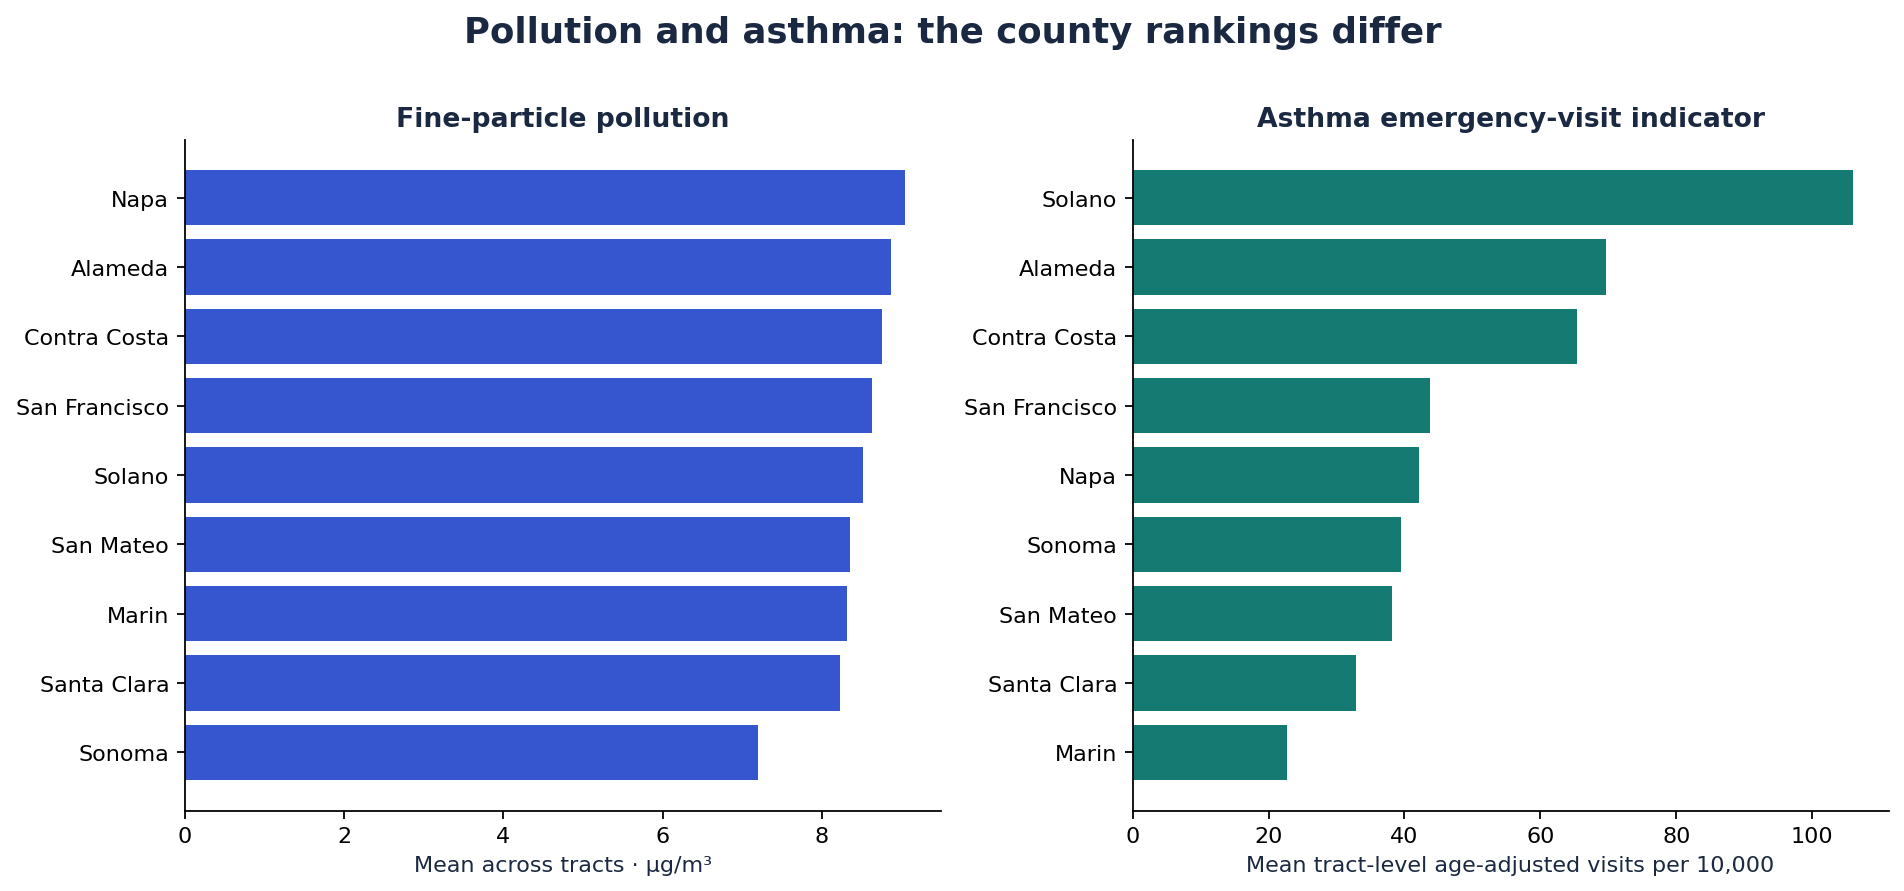

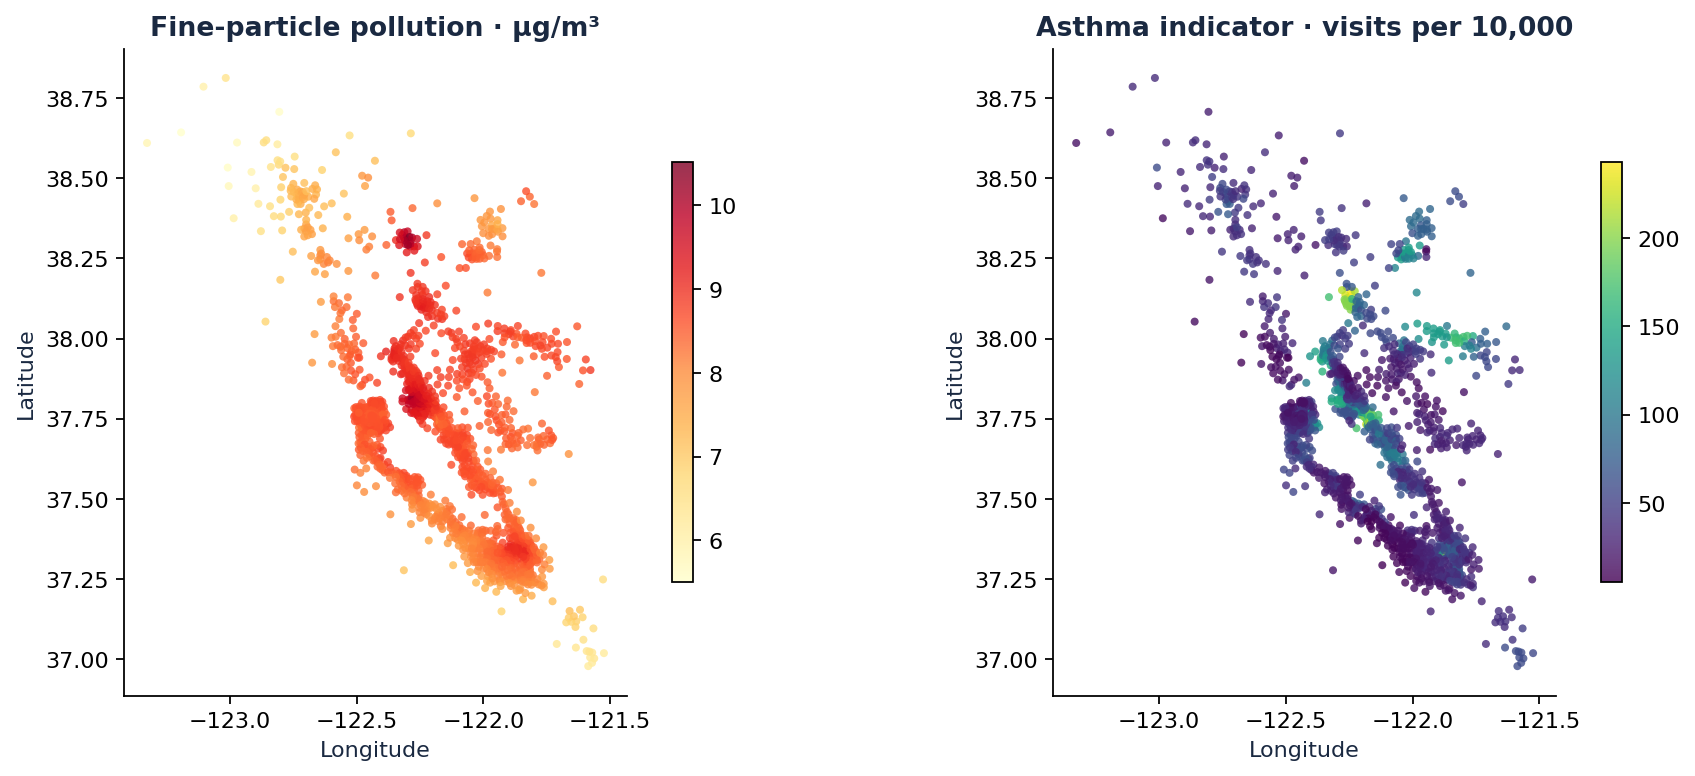

In [3]:
counties = county_summary(frame)
display(counties.sort_values(TARGET, ascending=False).round(4))
for feature in ['PM2.5', 'Ozone', 'Diesel PM', 'Pollution Burden', TARGET]:
    top = counties.loc[counties[feature].idxmax()]
    print(f"Highest mean {feature}: {top['county']} ({top[feature]:.4f})")
display(Image(filename=str(reports / 'figures' / 'county_comparison.png')))
display(Image(filename=str(reports / 'figures' / 'regional_maps.png')))

## 3. How to read the heatmap

Each square compares two measurements across tracts. A value near **+1** means they tend to rise together. Near **−1** means they tend to move in opposite directions. Near zero means little monotonic relationship.

We use Spearman rank correlation because many environmental measures are skewed. Each pair uses its nonmissing rows. These associations can reflect geography, income, measurement choices or other factors; they do not identify what caused the health outcome.

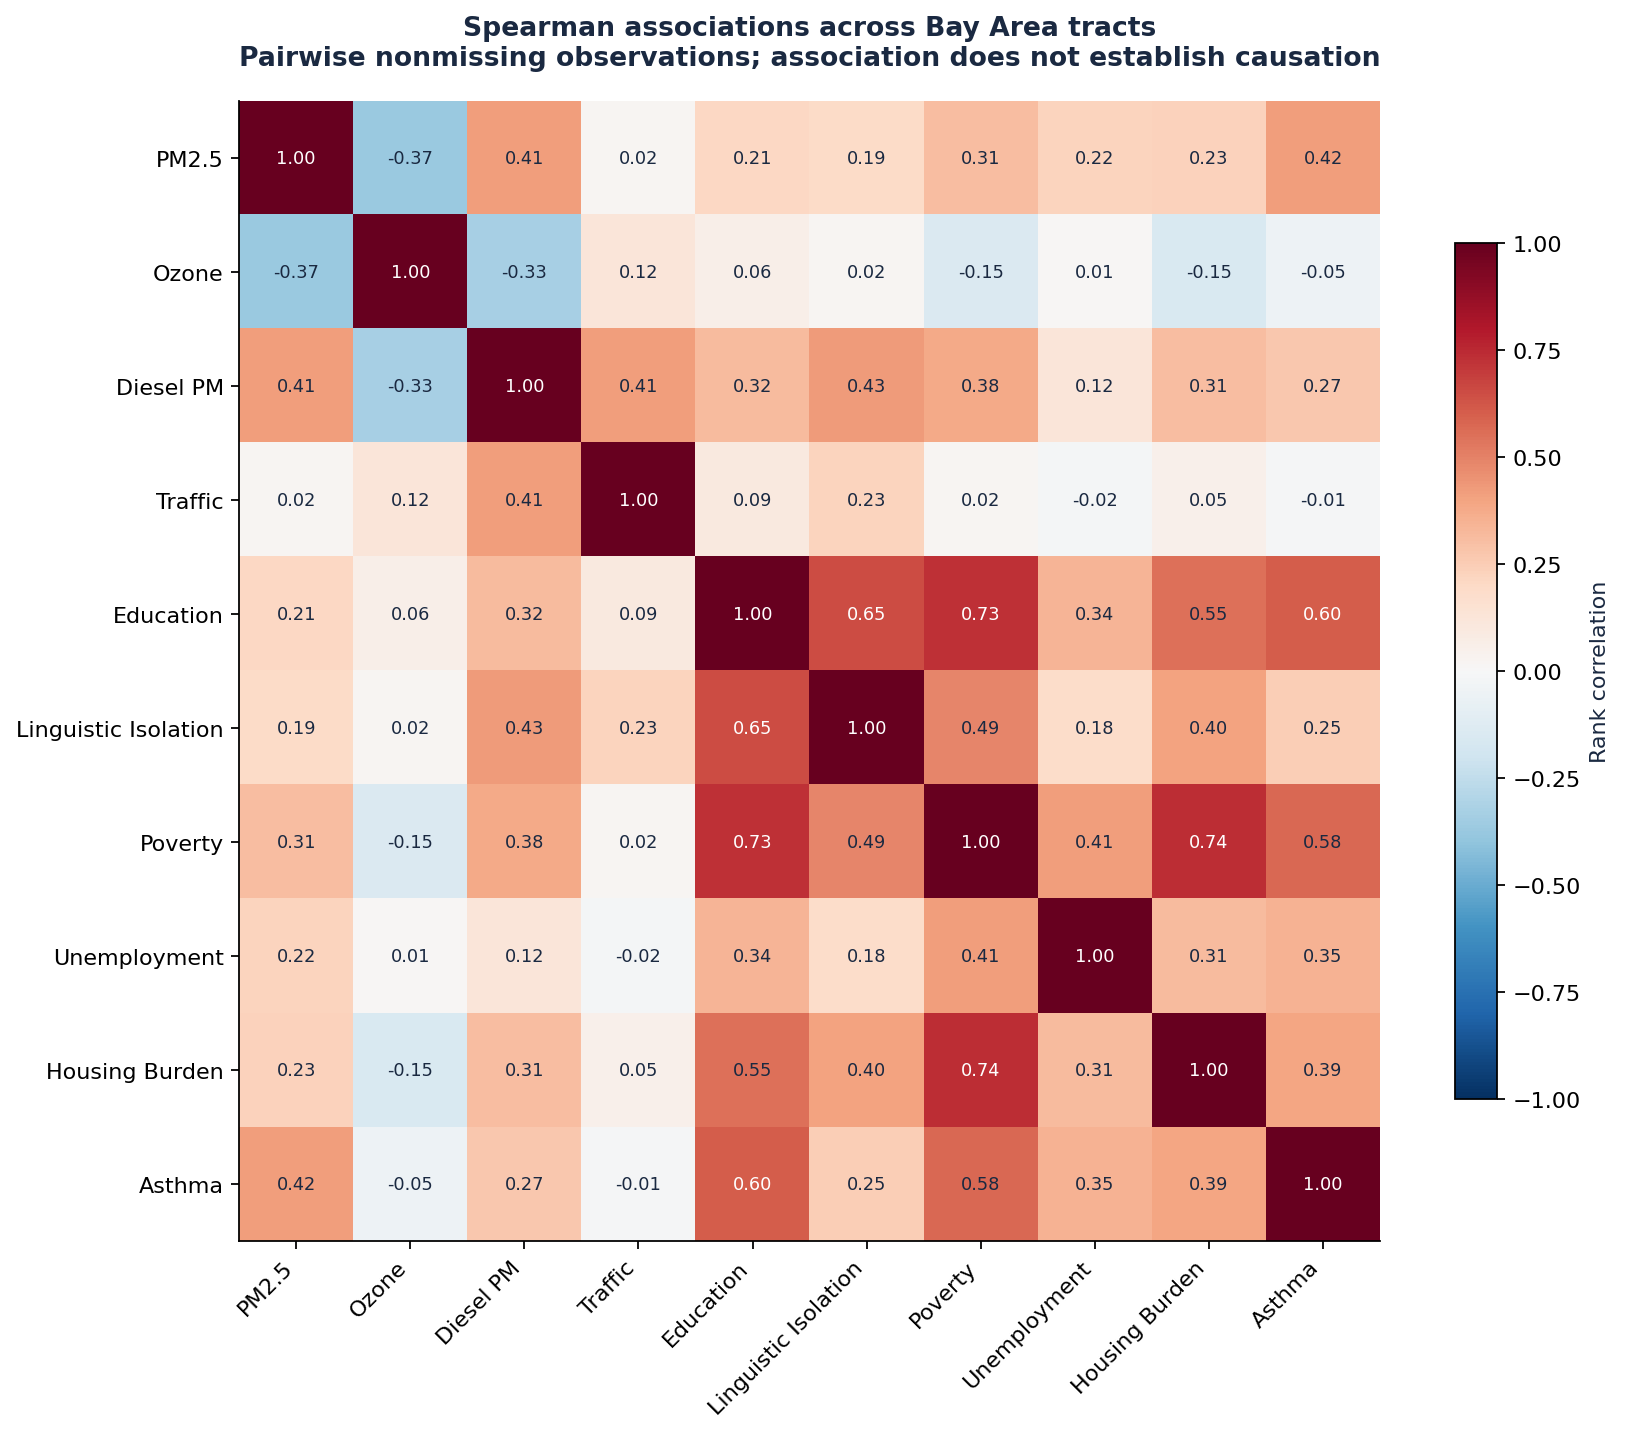

,Association with asthma indicator
Ozone,-0.053
Traffic,-0.012
Linguistic Isolation,0.246
Diesel PM,0.267
Unemployment,0.347
Housing Burden,0.391
PM2.5,0.417
Poverty,0.576
Education,0.603


In [4]:
display(Image(filename=str(reports / 'figures' / 'correlation_heatmap.png')))
corr = pd.read_csv(reports / 'spearman_correlations.csv', index_col=0)
display(corr[TARGET].drop(TARGET).sort_values().rename('Association with asthma indicator').to_frame().round(3))

## 4. Prevent a model from seeing the answer

The allowlists exclude the asthma percentile, population-characteristic and CES composites, other health outcomes, percentiles, dates, geographic identifiers and coordinates. Some excluded composites contain the target itself.

The three ablations are **air/traffic (4)**, **socioeconomic (5)** and **combined (18)**. Combined adds thirteen environmental measurements to the five social indicators. Coordinates are used for buffers and plots, not as predictors. Missing labels are excluded; predictor medians, missingness indicators and scaling are fitted only on training partitions.

In [5]:
display(pd.DataFrame({name: pd.Series(features) for name, features in OFFICIAL_FEATURES.items()}).fillna(''))
from bayair.advanced import advanced_candidates
for name, (estimator, grid) in advanced_candidates().items():
    print(name, type(estimator).__name__, grid)

,air,social,combined
0,PM2.5,Education,Ozone
1,Ozone,Linguistic Isolation,PM2.5
2,Diesel PM,Poverty,Diesel PM
3,Traffic,Unemployment,Drinking Water
4,,Housing Burden,Lead
5,,,Pesticides
6,,,Tox. Release
7,,,Traffic
8,,,Cleanup Sites
9,,,Groundwater Threats


median DummyRegressor {}
log_ridge TransformedTargetRegressor {'model__regressor__regressor__alpha': [1.0, 100.0, 1000.0]}
extra_trees ExtraTreesRegressor {'model__regressor__min_samples_leaf': [3, 12], 'model__regressor__max_features': [0.7, 1.0]}
boosting HistGradientBoostingRegressor {'model__regressor__max_leaf_nodes': [7, 15], 'model__regressor__l2_regularization': [1.0, 20.0], 'model__regressor__loss': ['squared_error', 'absolute_error']}


## 5. Give the model an unfamiliar county as its exam

For each of nine outer folds:

1. Hold out one whole county for testing.
2. Reserve two other counties for interval calibration.
3. Keep fitting centroids at least **5 km** from calibration and test centroids; calibration centroids also remain 5 km from test centroids.
4. Tune/select a model using three county-grouped, buffered inner folds.
5. Fit the chosen pipeline, calibrate its ranges, then score every tract in the test county.

The primary metric averages the nine county MAEs equally. Pooled metrics weight tracts equally. A five-kilometer centroid gap is not boundary separation and cannot establish independence of spatially modeled clinical indicators.

Fitting counties: ['Contra Costa', 'Napa', 'San Francisco', 'San Mateo', 'Solano', 'Sonoma']
Calibration counties: ['Marin', 'Santa Clara']
Test counties: ['Alameda']
Minimum fit/test distance: 5.19 km
Minimum fit/calibration distance: 5.13 km


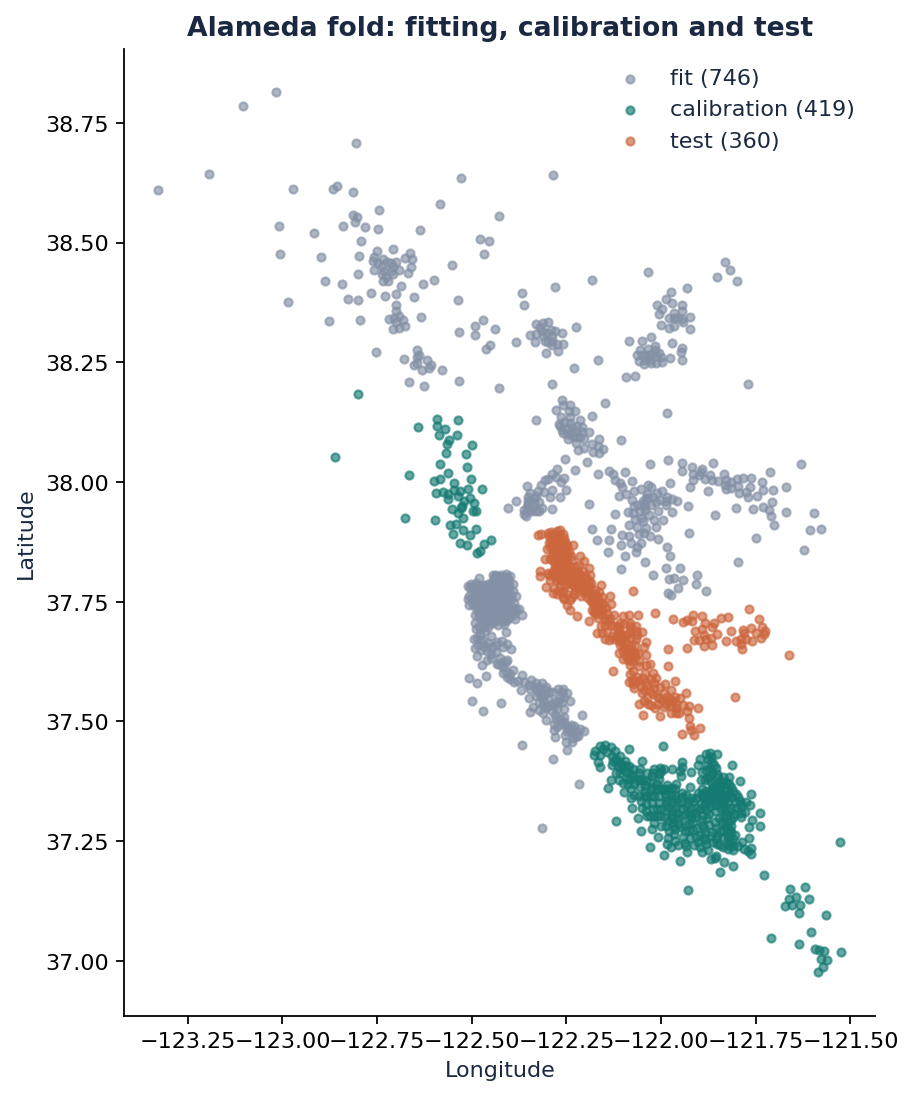

,feature_set,procedure,macro_county_mae,worst_county_mae,pooled_mae,pooled_rmse,pooled_r2,coverage_90,mean_interval_width
0,air,median,27.304,69.766,28.329,40.984,-0.082,0.856,100.054
1,air,selected,27.977,69.766,28.551,41.059,-0.086,0.856,98.786
2,combined,median,27.304,69.766,28.329,40.984,-0.082,0.856,100.054
3,combined,selected,27.400,68.293,25.814,39.157,0.013,0.837,82.080
4,combined,shuffled_labels,27.784,67.441,NaN,NaN,NaN,NaN,NaN
5,social,median,27.304,69.766,28.329,40.984,-0.082,0.856,100.054
6,social,selected,25.075,57.631,23.889,34.222,0.246,0.845,77.477


In [6]:
from bayair.spatial import bay_split, buffered_folds, nearest_km
fit, calibration, test = bay_split(labeled, 'Alameda')
print('Fitting counties:', sorted(fit[GROUP].unique()))
print('Calibration counties:', sorted(calibration[GROUP].unique()))
print('Test counties:', sorted(test[GROUP].unique()))
print('Minimum fit/test distance:', round(nearest_km(fit, test).min(), 2), 'km')
print('Minimum fit/calibration distance:', round(nearest_km(fit, calibration).min(), 2), 'km')
display(Image(filename=str(reports / 'figures' / 'spatial_split.png')))
run = json.loads((reports / 'run.json').read_text())
assert run['data_sha256'] == provenance['processed_sha256']
assert run['protocol_sha256'] == sha256(PROJECT / 'docs' / 'EVALUATION_PROTOCOL.md')
board = pd.read_csv(reports / 'leaderboard.csv')
display(board.round(3))

## 6. Keep failures visible

The first official-source experiment selected a log-target linear model that extrapolated to an implausible value above **260,000** for one held-out tract. That is a real robustness failure. Its results remain in `reports/failed_extrapolation`.

We then constrained predictions to `[0, maximum fitting target]`, with the maximum learned separately inside each fit, including inner CV. This prevents catastrophic output values but can underestimate a genuinely higher-rate unseen area.

**Because the guard was added after inspecting the held-out results, revised scores are exploratory.** Better code does not turn a previously inspected county into a new blind test. No test observation was discarded. Read the experiment log before quoting a score.

In [7]:
display(pd.read_csv(reports / 'failed_extrapolation' / 'leaderboard.csv').query("feature_set == 'combined'").round(3))
display(board.query("feature_set == 'combined'").round(3))
print((PROJECT / 'docs' / 'EXPERIMENT_LOG.md').read_text())

,feature_set,procedure,macro_county_mae,worst_county_mae,pooled_mae,pooled_rmse,pooled_r2,coverage_90,mean_interval_width
2,combined,median,27.304,69.766,28.329,40.984,-0.082,0.856,100.054
3,combined,selected,172.196,1337.318,196.811,6610.508,-28142.891,0.837,82.080
4,combined,shuffled_labels,27.784,67.441,NaN,NaN,NaN,NaN,NaN


,feature_set,procedure,macro_county_mae,worst_county_mae,pooled_mae,pooled_rmse,pooled_r2,coverage_90,mean_interval_width
2,combined,median,27.304,69.766,28.329,40.984,-0.082,0.856,100.054
3,combined,selected,27.400,68.293,25.814,39.157,0.013,0.837,82.080
4,combined,shuffled_labels,27.784,67.441,NaN,NaN,NaN,NaN,NaN


# Experiment log

## v2: draft-data audit

Original draft extract, random-vs-county diagnostics and nested county evaluation. Outputs retained in `reports/legacy`. This established the generalization problem and the need to verify provenance.

## v3.0: official Bay Area source, buffered calibration stress test

Defined `EVALUATION_PROTOCOL.md` before fitting. Used only the nine Bay Area counties. Official data ingestion revealed that asthma and PM2.5 agree with the draft extract, while many other environmental values differ. Exact reconciliation is saved.

The combined procedure selected log-target Ridge in some folds. Out-of-support environmental features caused extreme exponentiated predictions in a held-out county. The failed model's combined macro MAE was **172.20**, pooled R² **−28142.891**. This is a model robustness failure, not a reason to omit observations. Full first-run outputs are preserved in `reports/failed_extrapolation`.

## v3.1: training-derived extrapolation guard

A

## 7. What does each feature family add?

Compare air-only, social-only and combined procedures under the same buffered design. The combined model does not reliably beat the median baseline. The social-only ablation is more promising, but choosing it after looking at these counties does not create a fresh independent test score.

Inspect every county instead of hiding poor regions behind pooled R². The median baseline is part of inner model selection; choosing it is a valid outcome when a complex candidate lacks evidence.

,feature_set,procedure,macro_county_mae,worst_county_mae,pooled_mae,pooled_rmse,pooled_r2,coverage_90,mean_interval_width
1,air,selected,27.977,69.766,28.551,41.059,-0.086,0.856,98.786
3,combined,selected,27.400,68.293,25.814,39.157,0.013,0.837,82.080
6,social,selected,25.075,57.631,23.889,34.222,0.246,0.845,77.477


,county,family,n_fit,n_calibration,n_test,mae,r2
53,Solano,log_ridge,984,358,96,68.293,-1.307
11,Contra Costa,log_ridge,858,427,207,36.708,-0.148
4,Alameda,log_ridge,746,419,360,29.835,0.081
25,Napa,log_ridge,864,579,40,27.838,-11.666
18,Marin,log_ridge,858,579,55,23.129,-6.724
32,San Francisco,log_ridge,697,579,195,19.536,-0.204
46,Santa Clara,log_ridge,713,344,372,18.181,-0.901
60,Sonoma,boosting,975,363,99,11.736,-0.504
39,San Mateo,log_ridge,713,563,156,11.347,0.255


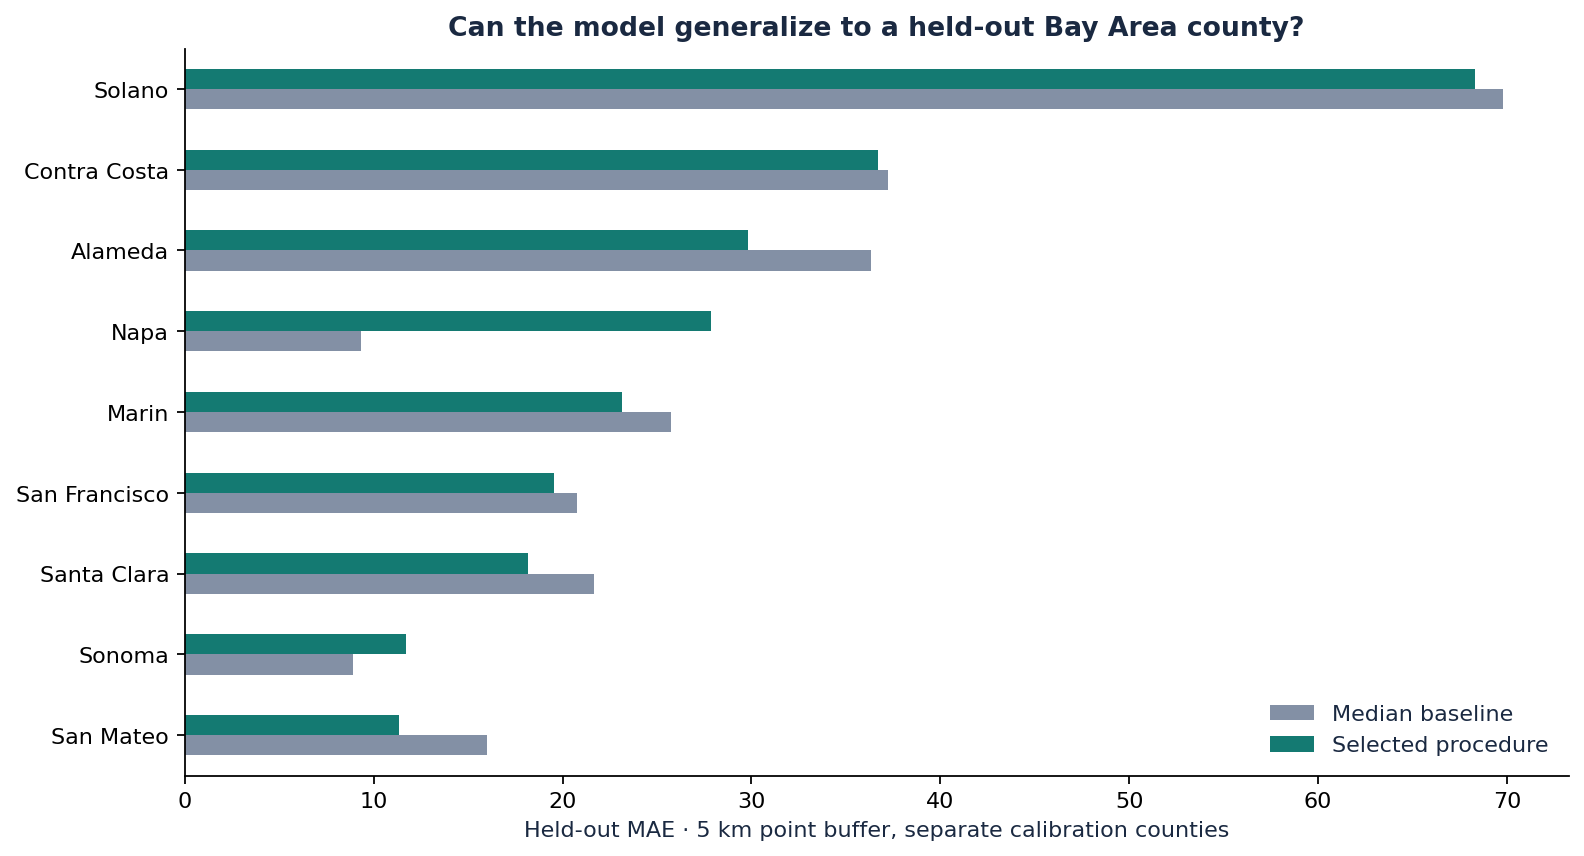

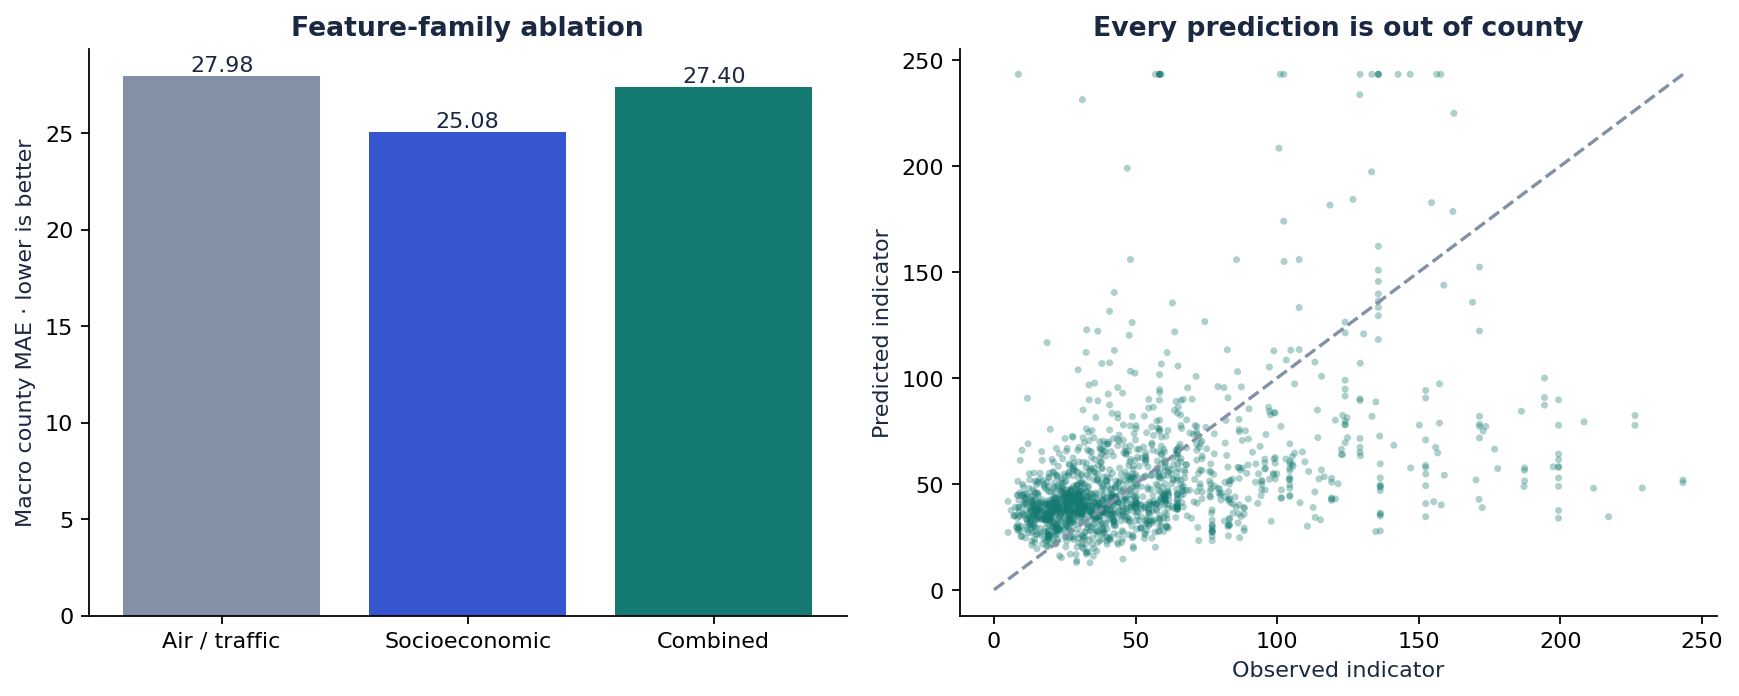

In [8]:
display(board.query("procedure == 'selected'").round(3))
folds = pd.read_csv(reports / 'county_metrics.csv')
display(folds.query("feature_set == 'combined' and procedure == 'selected'")[['county', 'family', 'n_fit', 'n_calibration', 'n_test', 'mae', 'r2']].sort_values('mae', ascending=False).round(3))
display(Image(filename=str(reports / 'figures' / 'county_errors.png')))
display(Image(filename=str(reports / 'figures' / 'ablation_and_fit.png')))

## 8. Does the uncertainty estimate hold up?

A point estimate can look precise even when the model is uncertain. Split-conformal ranges use errors from counties reserved exclusively for calibration. The 90% radius uses the finite-sample `(n+1)` order statistic rather than an interpolated percentile.

Exchangeability underlies standard coverage guarantees. Geography, dependence and shift violate that assumption here. We therefore report **actual coverage and width**, including undercoverage, rather than claiming the nominal 90% is guaranteed.

,county,coverage_90,mean_interval_width,radius_90
4,Alameda,0.656,59.389,29.694
11,Contra Costa,0.652,67.647,33.870
18,Marin,0.964,87.156,46.155
25,Napa,0.850,92.234,49.500
32,San Francisco,0.938,94.527,50.048
39,San Mateo,1.000,77.243,44.677
46,Santa Clara,0.976,99.687,57.128
53,Solano,0.656,110.843,72.342
60,Sonoma,1.000,76.898,45.856


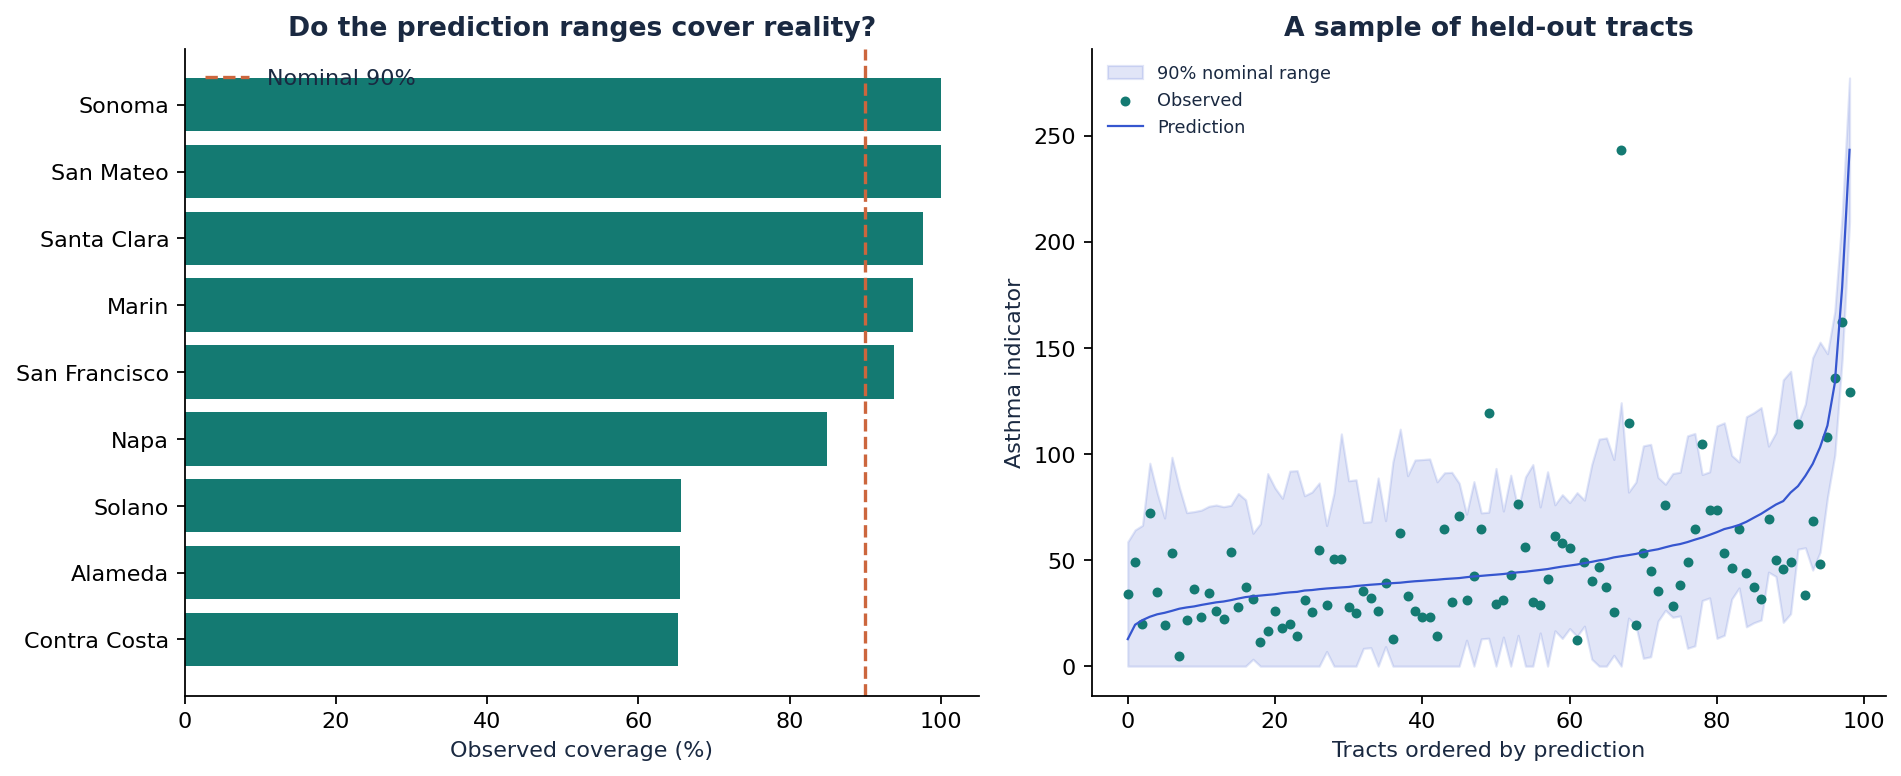

In [9]:
display(folds.query("feature_set == 'combined' and procedure == 'selected'")[['county', 'coverage_90', 'mean_interval_width', 'radius_90']].round(3))
display(Image(filename=str(reports / 'figures' / 'interval_coverage.png')))

## 9. Explain and diagnose

Permutation importance shuffles a feature on a held-out county and measures the MAE increase. Correlated features can share or mask reliance; these are not causal effects. Error bars show county variation.

The remaining diagnostics include residuals, geographic errors, fixed poverty slices, standardized feature shifts, a shuffled-label control and a learning curve. The learning curve uses selected hyperparameters and is diagnostic. County bootstrap stability is descriptive because only nine counties exist and training folds overlap.

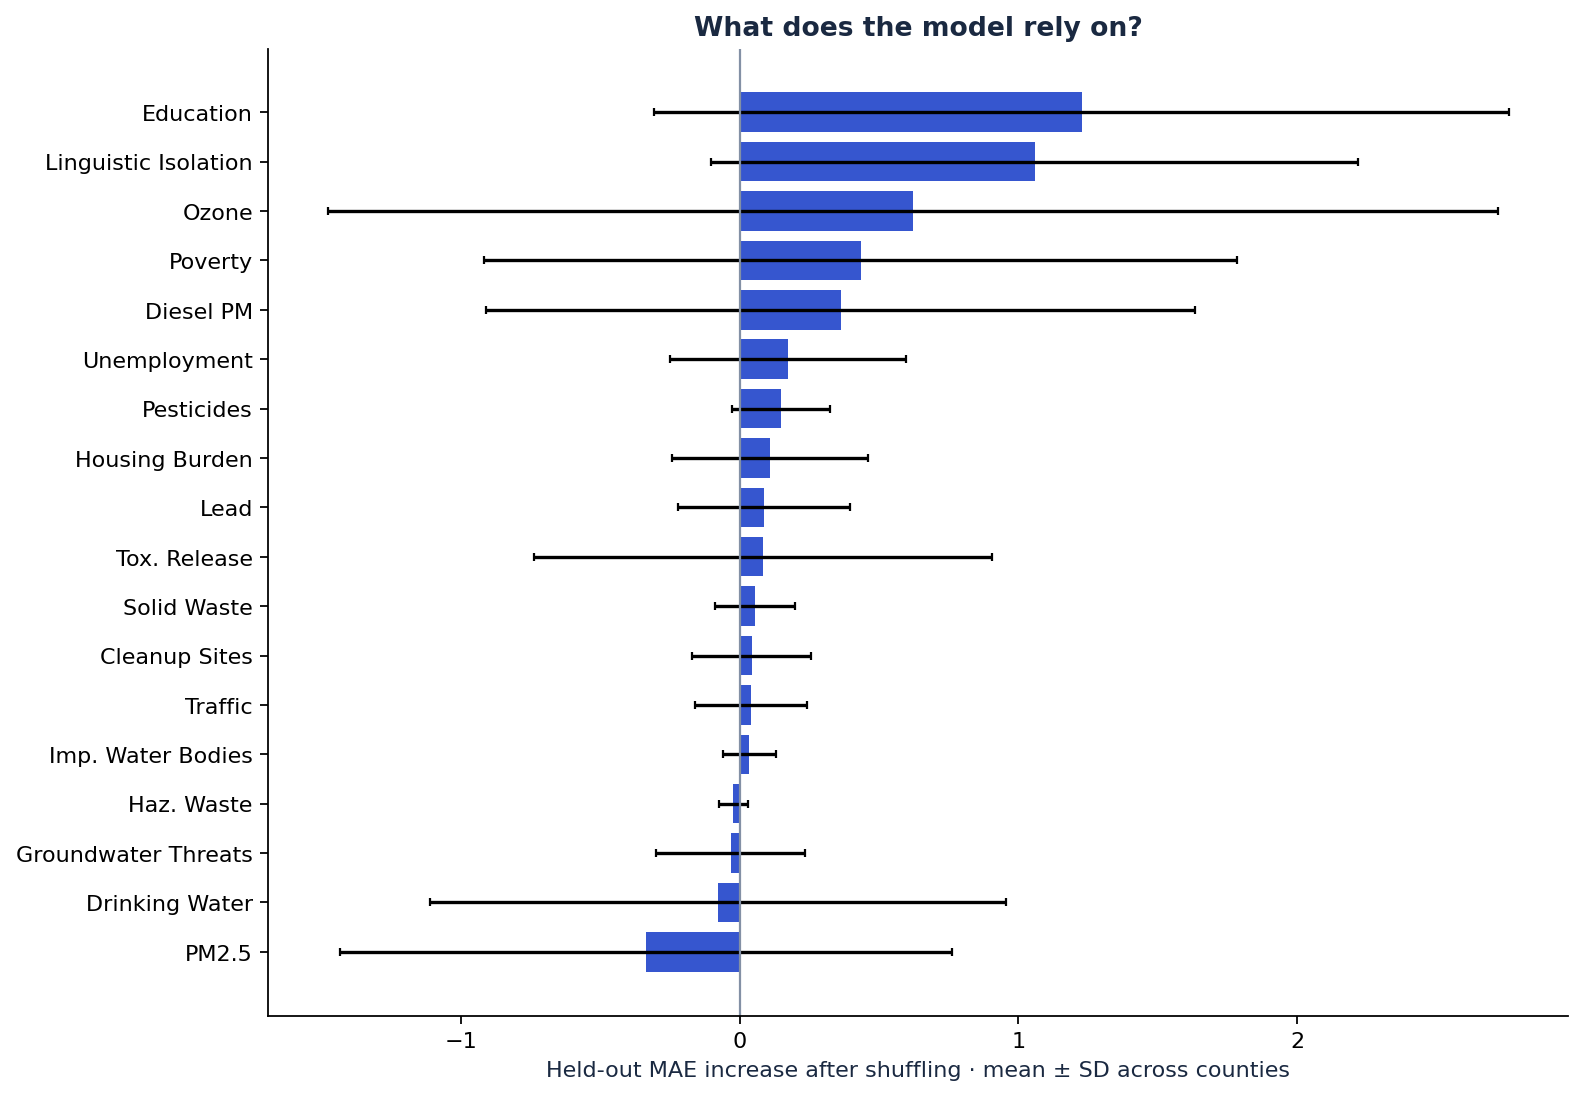

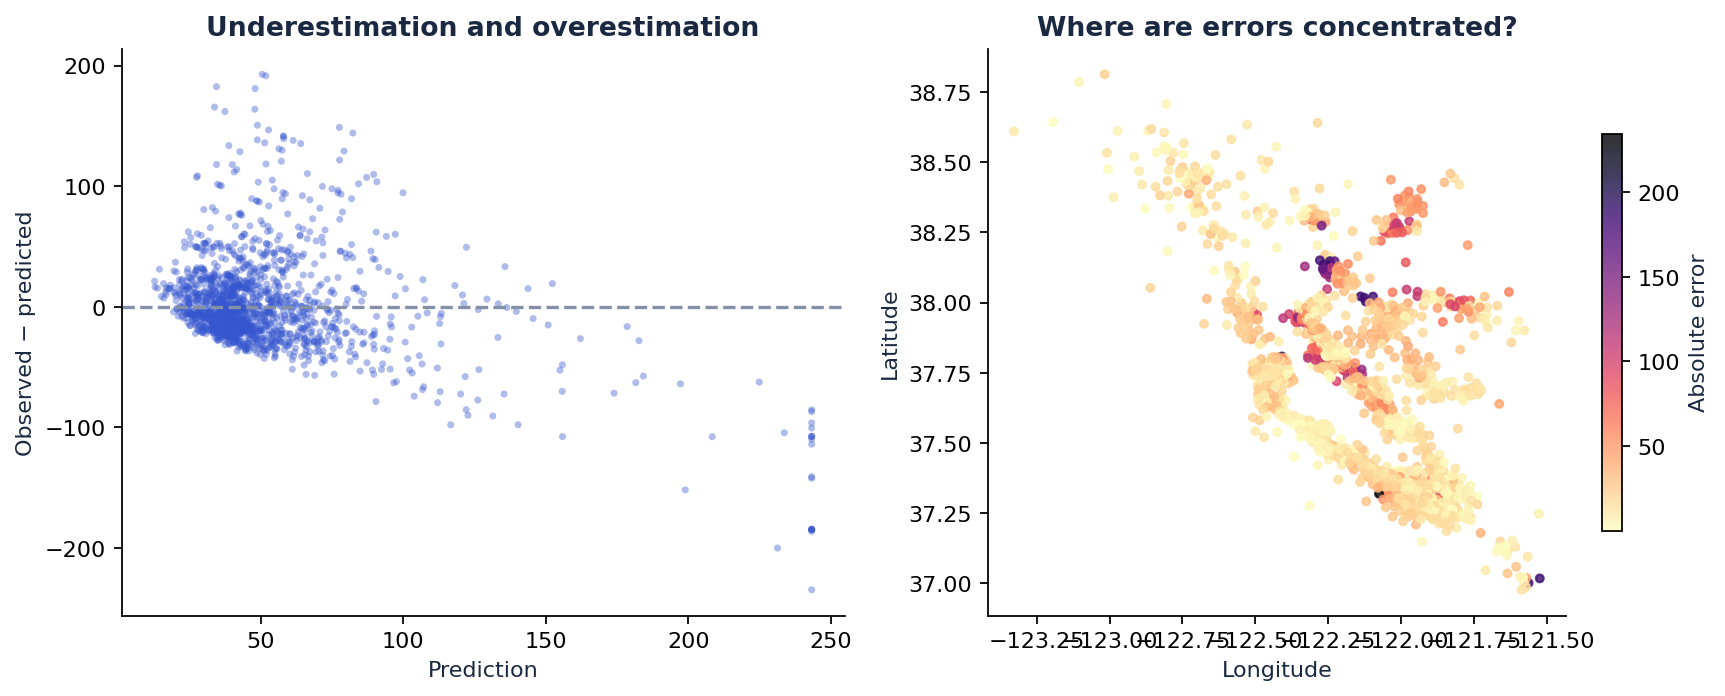

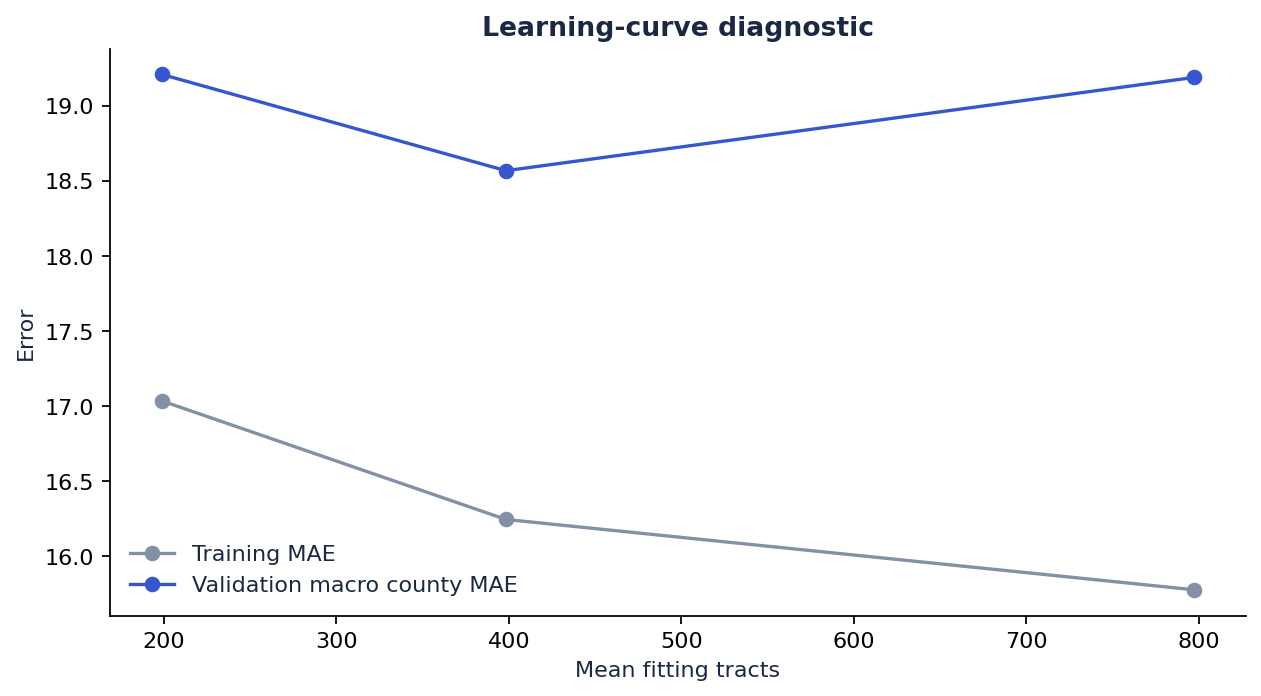

,poverty_slice,n,mae,mean_residual,coverage_90
0,<40%,1413,22.662,0.264,0.879
1,>=40%,160,52.622,0.941,0.469
2,Missing,7,49.169,30.456,0.714


,county,feature,standardized_mean_shift,outside_fit_range_fraction,test_missing_fraction,magnitude
24,Contra Costa,Tox. Release,2.479,0.048,0.0,2.479
145,Sonoma,PM2.5,-2.293,0.111,0.0,2.293
57,Napa,Drinking Water,1.986,0.025,0.0,1.986
74,San Francisco,Diesel PM,1.904,0.092,0.0,1.904
132,Solano,Tox. Release,1.633,0.000,0.0,1.633
108,Santa Clara,Ozone,1.206,0.000,0.0,1.206
54,Napa,Ozone,1.175,0.000,0.0,1.175
3,Alameda,Drinking Water,-1.020,0.003,0.0,1.020
150,Sonoma,Tox. Release,-1.000,0.071,0.0,1.000
72,San Francisco,Ozone,-0.977,0.000,0.0,0.977


{'macro_mae_improvement': -0.09666009223614284,
 'descriptive_95_percent_range': [-5.362390880381514, 3.531503802004706],
 'counties': 9,
 'repeats': 2000,
 'interpretation': 'County-resampled stability range, not a formal confidence interval; outer training sets overlap.'}

In [10]:
display(Image(filename=str(reports / 'figures' / 'importance.png')))
display(Image(filename=str(reports / 'figures' / 'residuals.png')))
display(Image(filename=str(reports / 'figures' / 'learning_curve.png')))
display(pd.read_csv(reports / 'slice_metrics.csv').round(3))
display(pd.read_csv(reports / 'distribution_shift.csv').assign(magnitude=lambda d:d.standardized_mean_shift.abs()).nlargest(10, 'magnitude').round(3))
display(json.loads((reports / 'stability.json').read_text()))

## 10. Reproduce and inspect inference

The final demonstration pipeline is trained with two counties reserved for calibration. Its point predictions and nominal ranges can be generated with `python run_bayair.py predict --input ... --output ...`. It flags individual feature values outside fitting ranges and counts missing predictors, but those checks do not detect every unsupported combination.

The final artifact has no fresh independent test set. The outer scores evaluate the learning procedure, not a new test of this artifact. Tests verify scope, source integrity, real five-kilometer separation, finite-sample quantiles, extrapolation bounds, serialization and agreement between reported metrics and predictions.

The source, protocol and package version hashes are recorded below. Future confirmatory claims need genuinely new observations within an appropriate study design; this work stays within the Bay Area scope.

In [11]:
display(run)
display(Markdown((reports / 'RESULTS.md').read_text()))
print('Offline interactive explorer:', reports / 'index.html')

{'version': '3.1.0',
 'evaluation_status': 'Exploratory post-inspection robustness revision; initial failed results preserved',
 'scope': 'Nine Bay Area counties only',
 'seed': 42,
 'buffer_km': 5,
 'outer_folds': 9,
 'inner_folds': 3,
 'nominal_coverage': 0.9,
 'raw_bay_area_rows': 1581,
 'labeled_rows': 1580,
 'data_sha256': '6b47d2b2c392dd4eea865c99056b81b939ef0a11b79d944f89bfcd54e769360f',
 'protocol_sha256': 'ed166820056cc5fa96c40f2d0140a8ff8e826cea20d31aac9b5ce8d4efc7956b',
 'code_sha256': {'__init__.py': 'd658804bd217f733b2da899e3350703a689772e0e96095ed3e86247d75e298ed',
  'advanced.py': '908848c1a0bd2b91c85872be467b7fc02ba0fc077b9c86e98fb9e043642cc8e1',
  'benchmark.py': '24f03305d0ed25a06ed7c1a1bb114f79eb8dda667d7b9ee859e29804728794cc',
  'cli.py': '843d960286b2d31822e48db5f25829bd672c5127c44f476de94812421605db14',
  'data.py': '97b6425286315f6adebf168307bb319e7d176ed0c9b971af1450c4efc4092257',
  'experiment.py': '64bc84f214d3375e0014dd9dacba68c8d054c4cc61c7544a04d128b3aa59a3

# Bay Area findings — official CES 4.0 final source

## Regional questions

- Highest mean PM2.5: **Napa (9.04 µg/m³)**.
- Highest mean ozone: **Solano (0.04014 ppm)**.
- Highest mean diesel PM: **San Francisco (0.719 tons/year/km²)**.
- Highest mean tract-level asthma ED indicator: **Solano (105.95 age-adjusted visits per 10,000)**.

These are unweighted tract averages in a historical release, not official aggregated county rates or current conditions. One tract has no asthma label. Pollution burden is a broader environmental composite, not an air-only measurement.

## Buffered nested evaluation

Combined selected procedure: macro county MAE **27.40**; median baseline **27.30**. Pooled R² **0.013**. Nominal 90% intervals cover **83.7%** of held-out observations; mean width **82.08** indicator units.

All training, tuning, calibration and testing use only the nine Bay Area counties. Each outer test county is excluded from every fit operation, and fitting/calibration/test points are separated by 5 km. Three county-grouped buffered inner folds select model family/parameters. Two other counties supply interval calibration; they are not used in fitting/tuning. This is a harder and smaller-data task than v2; score changes cannot be attributed to one change alone.

| Feature family | Macro county MAE | Pooled R² | Empirical interval coverage |
|---|---:|---:|---:|
| air | 27.98 | -0.086 | 85.6% |
| social | 25.08 | 0.246 | 84.5% |
| combined | 27.40 | 0.013 | 83.7% |

## Every held-out county, combined procedure

| County | Model family | MAE | R² | Coverage |
|---|---|---:|---:|---:|
| Solano | log_ridge | 68.29 | -1.307 | 65.6% |
| Contra Costa | log_ridge | 36.71 | -0.148 | 65.2% |
| Alameda | log_ridge | 29.83 | 0.081 | 65.6% |
| Napa | log_ridge | 27.84 | -11.666 | 85.0% |
| Marin | log_ridge | 23.13 | -6.724 | 96.4% |
| San Francisco | log_ridge | 19.54 | -0.204 | 93.8% |
| Santa Clara | log_ridge | 18.18 | -0.901 | 97.6% |
| Sonoma | boosting | 11.74 | -0.504 | 100.0% |
| San Mateo | log_ridge | 11.35 | 0.255 | 100.0% |

## Evaluation status: exploratory robustness revision

The first official-data run exposed extreme log-target extrapolation (combined macro MAE 172.20). The model was then constrained to the range [0, maximum fitting target], learned independently inside each fit. First-run outputs remain in `failed_extrapolation/`. Because the guard was added after inspecting held-out results, the revised scores are exploratory, not untouched confirmatory evidence. No observation was removed from scoring. See `docs/EXPERIMENT_LOG.md` for the revision rationale.

## What these results mean

Point predictions and interval calibration face geographic shift. Nominal 90% split-conformal coverage is not guaranteed for dependent, nonexchangeable counties; measured coverage is the relevant diagnostic. Wide intervals or undercoverage are findings, not reasons to hide a fold. The bootstrap in `stability.json` is descriptive because training folds overlap and only nine counties exist.

Permutation importance measures predictive reliance, not causal effects. Socioeconomic slices do not establish clinical fairness. The learning curve uses fixed hyperparameters selected on the same development data and is a diagnostic, not an independent performance estimate. The shuffled-label control refits with fitting labels shuffled only within each fitting partition.

The original draft extract and v2 outputs remain under `reports/legacy`; reconciliation quantifies final-release differences. A new official source does not make already explored regional outcomes blinded. No result here establishes individual clinical risk, pollution causation, future forecasting, or readiness for public-health decisions. The final artifact has separate calibration counties but no fresh independent test set.


Offline interactive explorer: /Users/ronishshrestha/Documents/ChatGPT/career/bay-area-data-projects/Bay_Area_Health_and_Pollution_Analysis/reports/index.html
